# Composing and sharing mathematical figures

A useful figure can answer two questions at once: **what did we compute, and which part should I look at?** A scalar background supplies context; a signed contribution or selected representative points to a feature. Combining these views is helpful only if their coordinates and claims still agree.

Here we make one signed-overlay figure, connect a retained cycle to its interval, and attach an explanation to an algebraic coefficient. These are independent library workflows: they do not require a new mathematical lesson or a live browser. Familiarity with a matrix and a barcode is enough. Install TamerOp and CairoMakie in your environment; the [installation page](../src/start/install.md) explains the setup. For the objects behind these pictures, see [slices and signed summaries](slices_diagrams.ipynb) and [source cells](source_cells.ipynb).

In [1]:
import TamerOp as OP
using CairoMakie
A = OP.Advanced

TamerOp.Advanced

## Put changes in dimension back in context

Take the sum of two square-supported modules, on $[0,2)^2$ and $[1,3)^2$. The dimension is two on their overlap and one where only one square remains. We sample those dimensions on a grid. This example supplies the scalar table directly from the two support formulas; it does not infer a module from an image.

Predict where negative signed atoms will appear. They mark decreases in cumulative dimension, rather than negative-dimensional vector spaces.

In [2]:
xs = [-1, 0, 1, 2, 3, 4]
ys = [-1, 0, 1, 2, 3, 4]
dimensions = [Int(0 <= x < 2 && 0 <= y < 2) +
              Int(1 <= x < 3 && 1 <= y < 3) for x in xs, y in ys]
atoms = OP.SignedMeasures.point_signed_measure(dimensions, (xs, ys))
@assert dimensions[3, 3] == 2
OP.describe(atoms)

(kind = :point_signed_measure, ambient_dimension = 2, axis_lengths = (6, 6), nterms = 8, positive_terms = 4, negative_terms = 4, total_mass = 0, total_variation = 8, largest_terms = [(index = (2, 2), point = (0, 0), weight = 1), (index = (4, 2), point = (2, 0), weight = -1), (index = (3, 3), point = (1, 1), weight = 1), (index = (5, 3), point = (3, 1), weight = -1), (index = (2, 4), point = (0, 2), weight = -1)])

A `VisualContext` names the domain, units and dataset shared by the two views. It also records field and degree when they are relevant. Matching declarations permit composition; they are not a theorem that independently supplied data are correct. Here the signed measure is calculated from this very table, so we can check its cumulative sum independently.

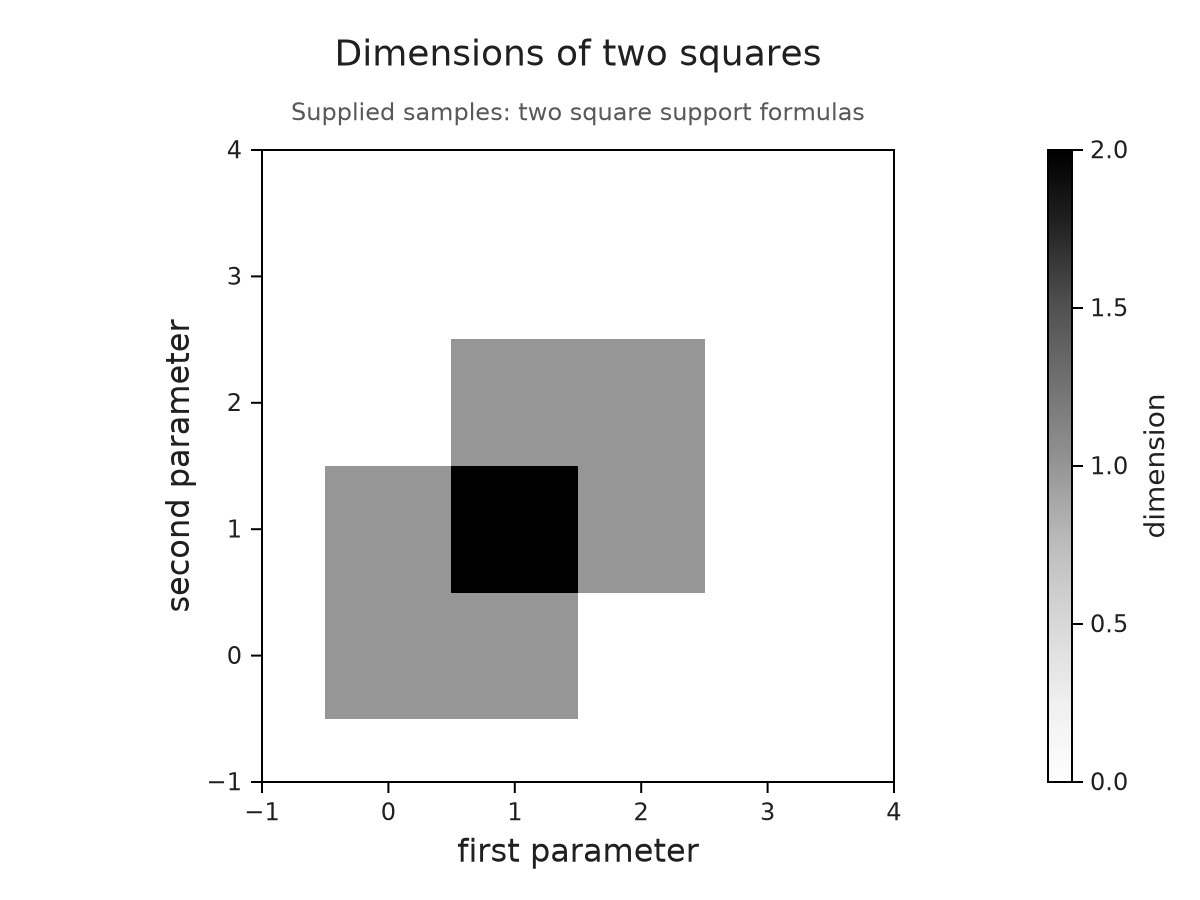

In [3]:
context = OP.VisualContext(domain="two-square parameter plane",
    units=("first parameter", "second parameter"), provenance="two square support formulas")
for (i, x) in enumerate(xs), (j, y) in enumerate(ys)
    reconstructed = sum((w for (p, w) in zip(OP.SignedMeasures.points(atoms),
        OP.SignedMeasures.weights(atoms)) if p[1] <= x && p[2] <= y); init=0)
    @assert reconstructed == dimensions[i, j]
end
background = OP.visual_panel(permutedims(dimensions); x=xs, y=ys,
    quantity="dimension", context, title="Dimensions of two squares")
OP.visualize(background)

Rows in a scalar picture follow the vertical coordinate, so we transpose the table whose first index was $x$. These are **samples**: the shading uses cells around them and is not a certified drawing of every half-open support boundary. The signed atom positions themselves are the actual grid coordinates.

The overlay retains the two named layers in back-to-front order. We set the same visible window because otherwise the atom-only view would crop away part of the background.

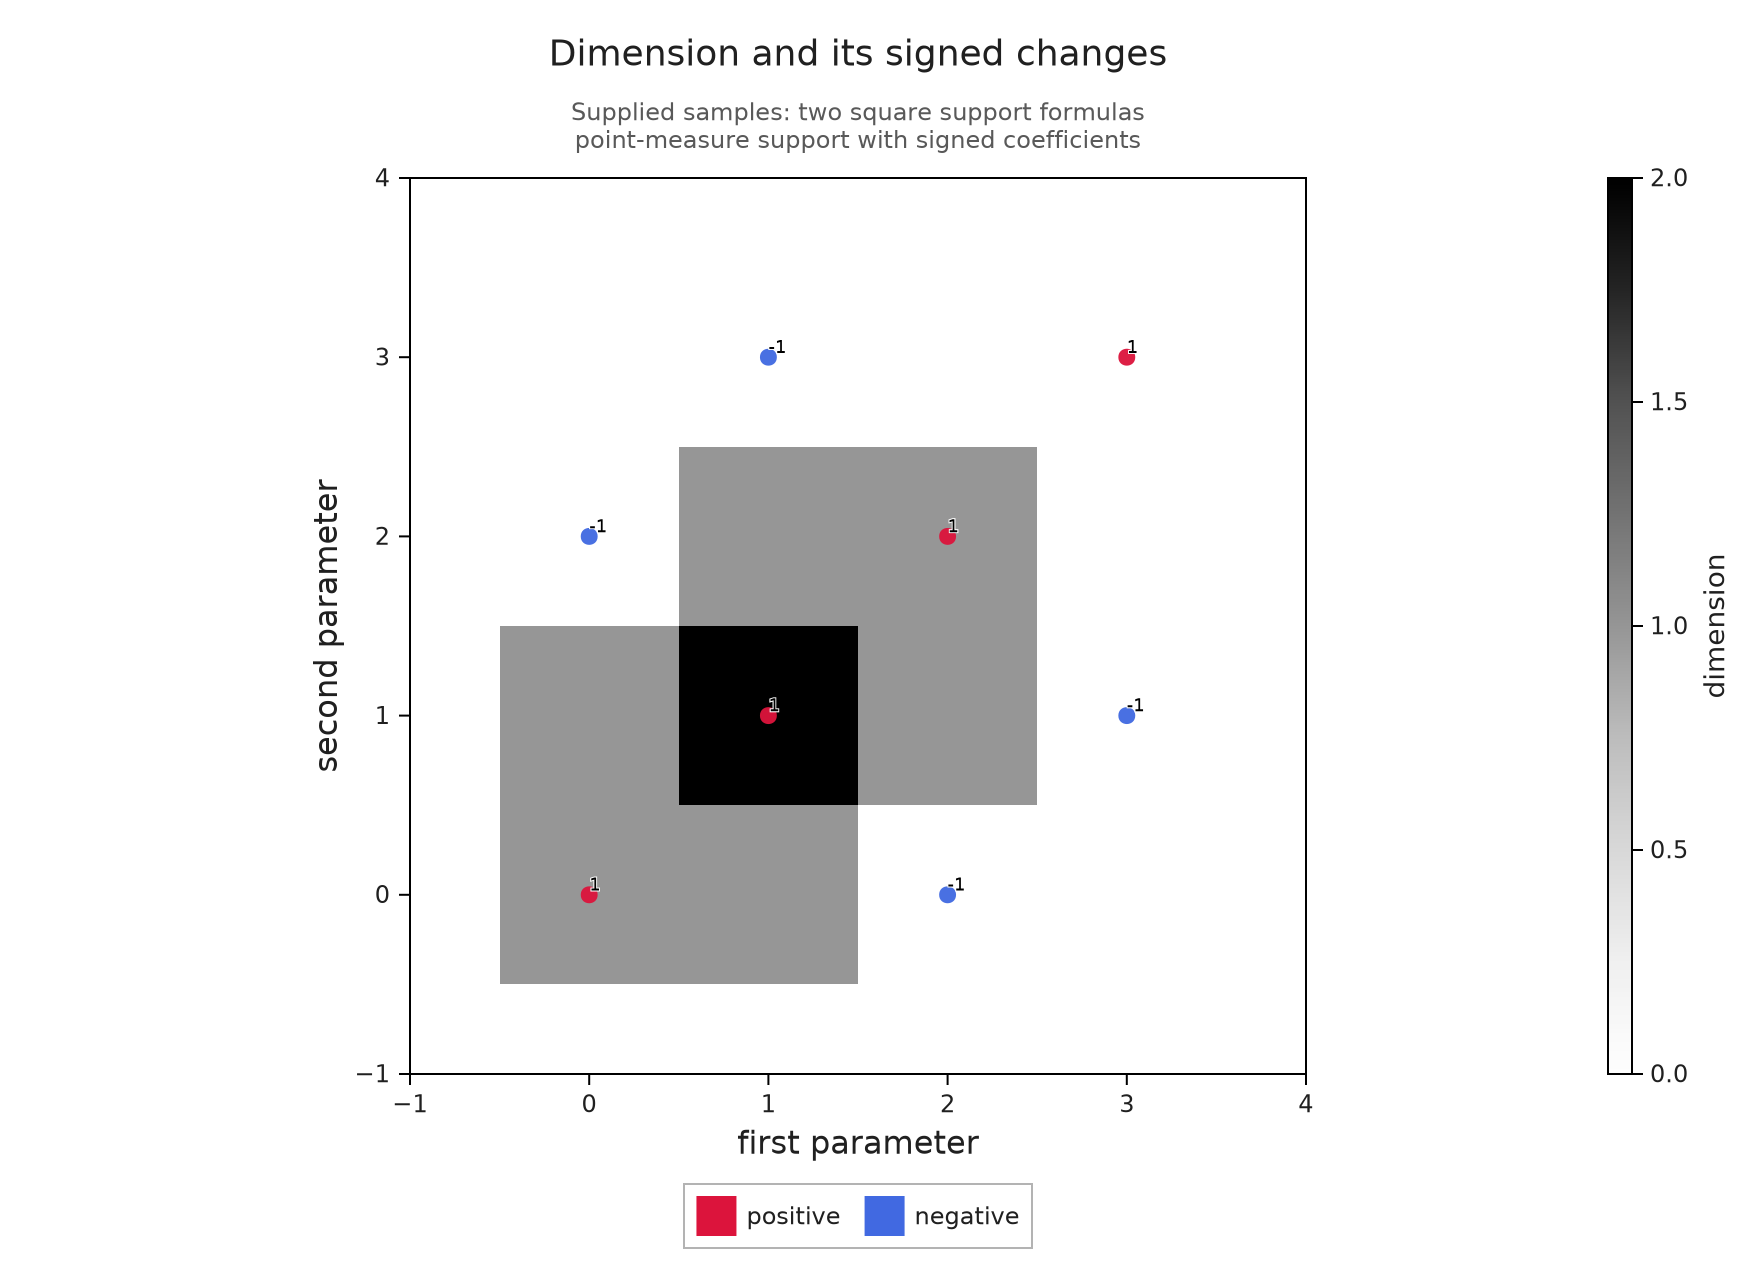

In [4]:
signed = OP.visual_panel(atoms; kind=:signed_atoms, context,
    limits=(x=(-1, 4), y=(-1, 4)))
overlay = OP.overlay_visuals((dimensions=background, changes=signed);
    title="Dimension and its signed changes")
OP.visualize(overlay)

The gray shade answers “what is the stalk dimension?” The red and blue atoms answer “which signed changes reconstruct that number?” At a query point, sum all atom weights below it in both coordinates. The assertions above establish that answer at every sampled grid point.

We can explain the overlap without claiming that the explanation itself was computed. A highlight is bounded by two data coordinates. Its dashed style and the figure key identify it as an authored annotation.

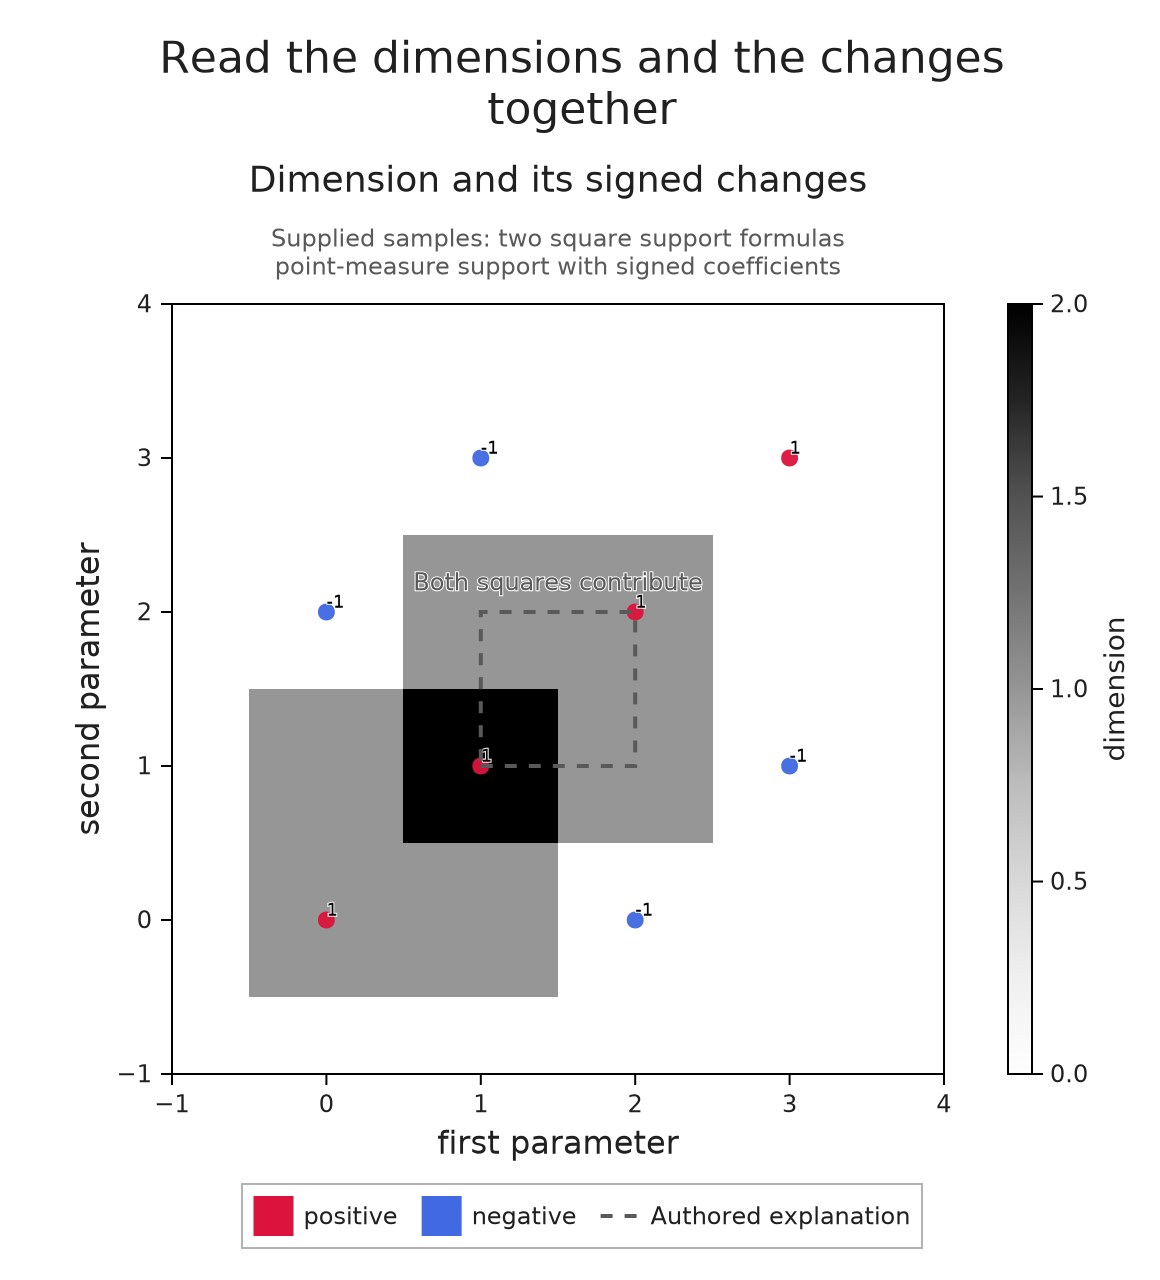

In [5]:
overlap_note = OP.VisualAnnotation(
    OP.VisualAnchor(:summary; point=(1, 1)),
    OP.VisualAnchor(:summary; point=(2, 2));
    kind=:highlight, label="Both squares contribute")
summary_figure = OP.compose_visuals((summary=overlay,);
    annotations=(overlap_note,), title="Read the dimensions and the changes together")
OP.visualize(summary_figure)

## Connect a class to the source that represents it

An arrow from a hole to a barcode needs more than a pair of coordinates. We retain the original cells and a cycle chosen by persistence reduction. In a $3\times3$ top-cell image the eight outer squares appear at zero and the central square at five. The hole therefore gives the interval $[0,5)$; at scale two it is still present.

In [6]:
image = zeros(Int, 3, 3)
image[2, 2] = 5
diagram = OP.cubical_persistence(image; input=:top_cells,
    source=true, representatives=true)
representative = A.persistence_representative(diagram; dim=1, scale=2)
cycle = representative.source_cycle
@assert representative.interval == (0, 5)
OP.describe(cycle)

(kind = :source_chain, chain_kind = :cycle, dimension = 1, parameter = (2,), field = TamerOp.CoreModules.CoeffFields.PrimeField(2), cell_count = 24, support = 4, metadata = (correspondence = :verified_chain_map, certificate = :equal_grade_contraction, choice = :noncanonical_f2_column_reduction, equation = :checked_on_source, optimization = :none, interval = (0, 5), interval_kind = :finite, member = 1))

The source panel draws that cycle's nonzero coefficients on original cells. The barcode panel retains the interval member identity even when several equal bars are grouped. `correspondence_annotation` checks that the cycle really is the retained representative of that interval in this diagram. It rejects an independently computed diagram or an unrelated cycle, even if the picture looks the same.

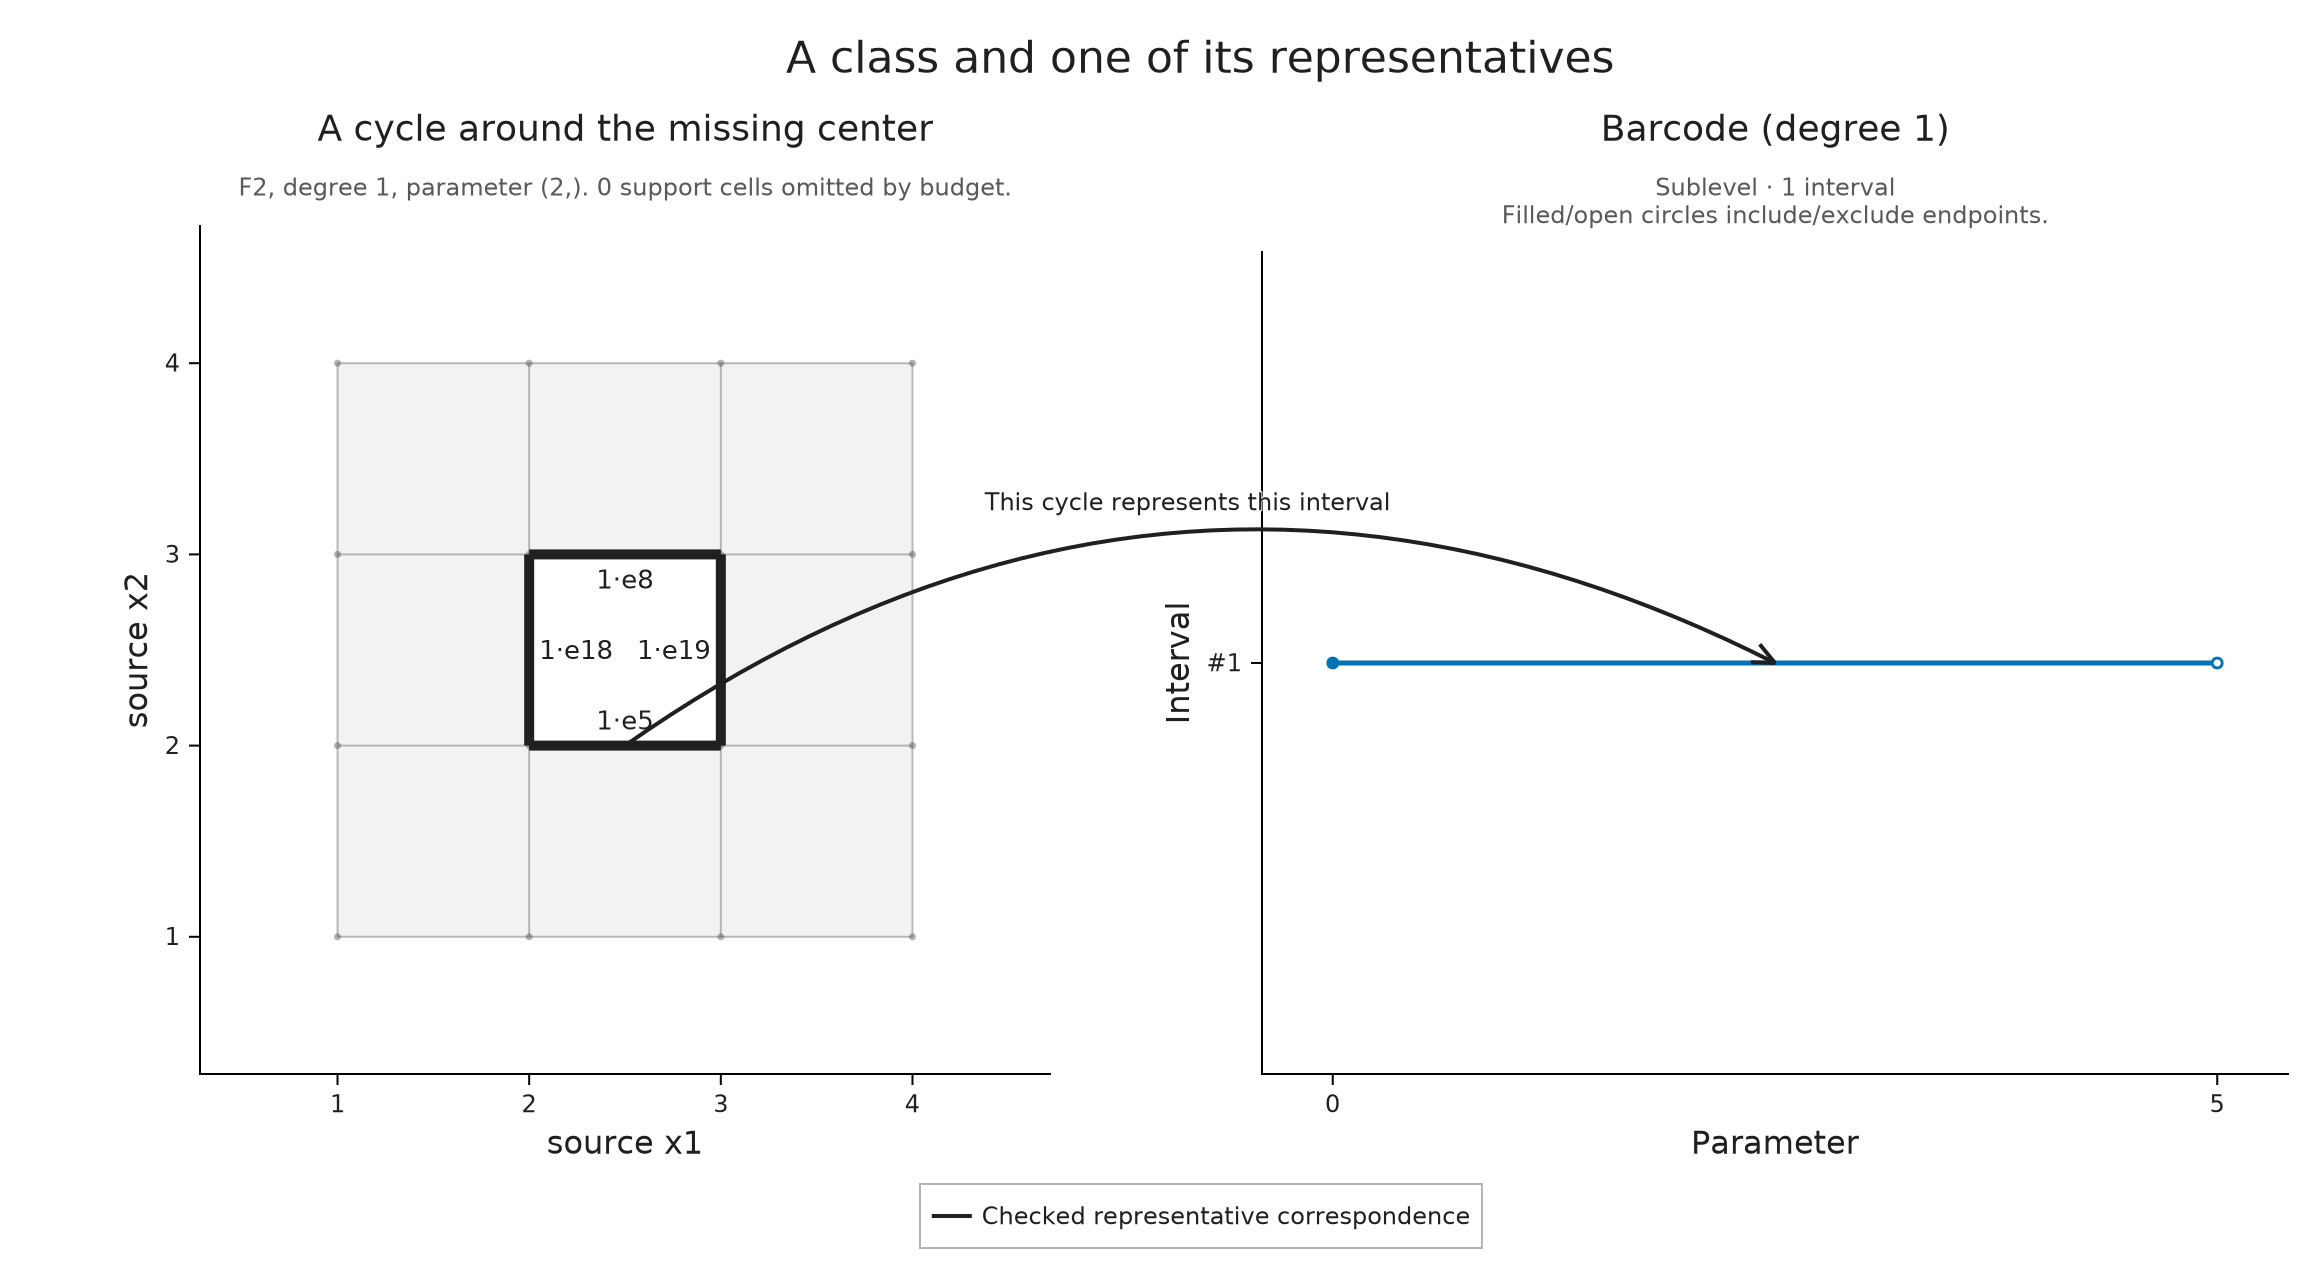

In [7]:
source = OP.visual_panel(cycle; title="A cycle around the missing center")
barcode = OP.visual_panel(diagram; kind=:barcode, dim=1)
connection = OP.correspondence_annotation(diagram, cycle;
    label="This cycle represents this interval", curve=0.15)
source_figure = OP.compose_visuals((source=source, barcode=barcode);
    annotations=(connection,), title="A class and one of its representatives")
OP.visualize(source_figure)

The solid arrow certifies this specific retained correspondence. It does not make the cycle canonical, shortest, or a global multiparameter summand. Change the scale to four and the class is still alive; scale five is outside the interval and the representative query is rejected.

Panel names are stable identities. Changing their order, inserting another panel, or choosing a different figure size does not require recalculating the arrow endpoints. If a drawing budget omits the chosen cell or interval, composition rejects the missing anchor instead of redirecting it.

## Relate source geometry to a parameter support

A source-to-support composition can also carry an authored mathematical explanation. On $\mathbb{R}\times[0,\infty)$, pull the radius interval back along the first coordinate, then extend by zero to the rest of the plane. The resulting model has a one-dimensional stalk for $0\le r<5$ and $s\ge0$. This is a declared zero-extended pullback of the ordinary interval; it is not a decomposition inferred from a point cloud. The shaded table samples that support on a finite viewing window.

The dashed connector explains this declared construction. Unlike the solid retained-cycle connector, it is not a certificate produced by a general source-to-encoding correspondence algorithm.


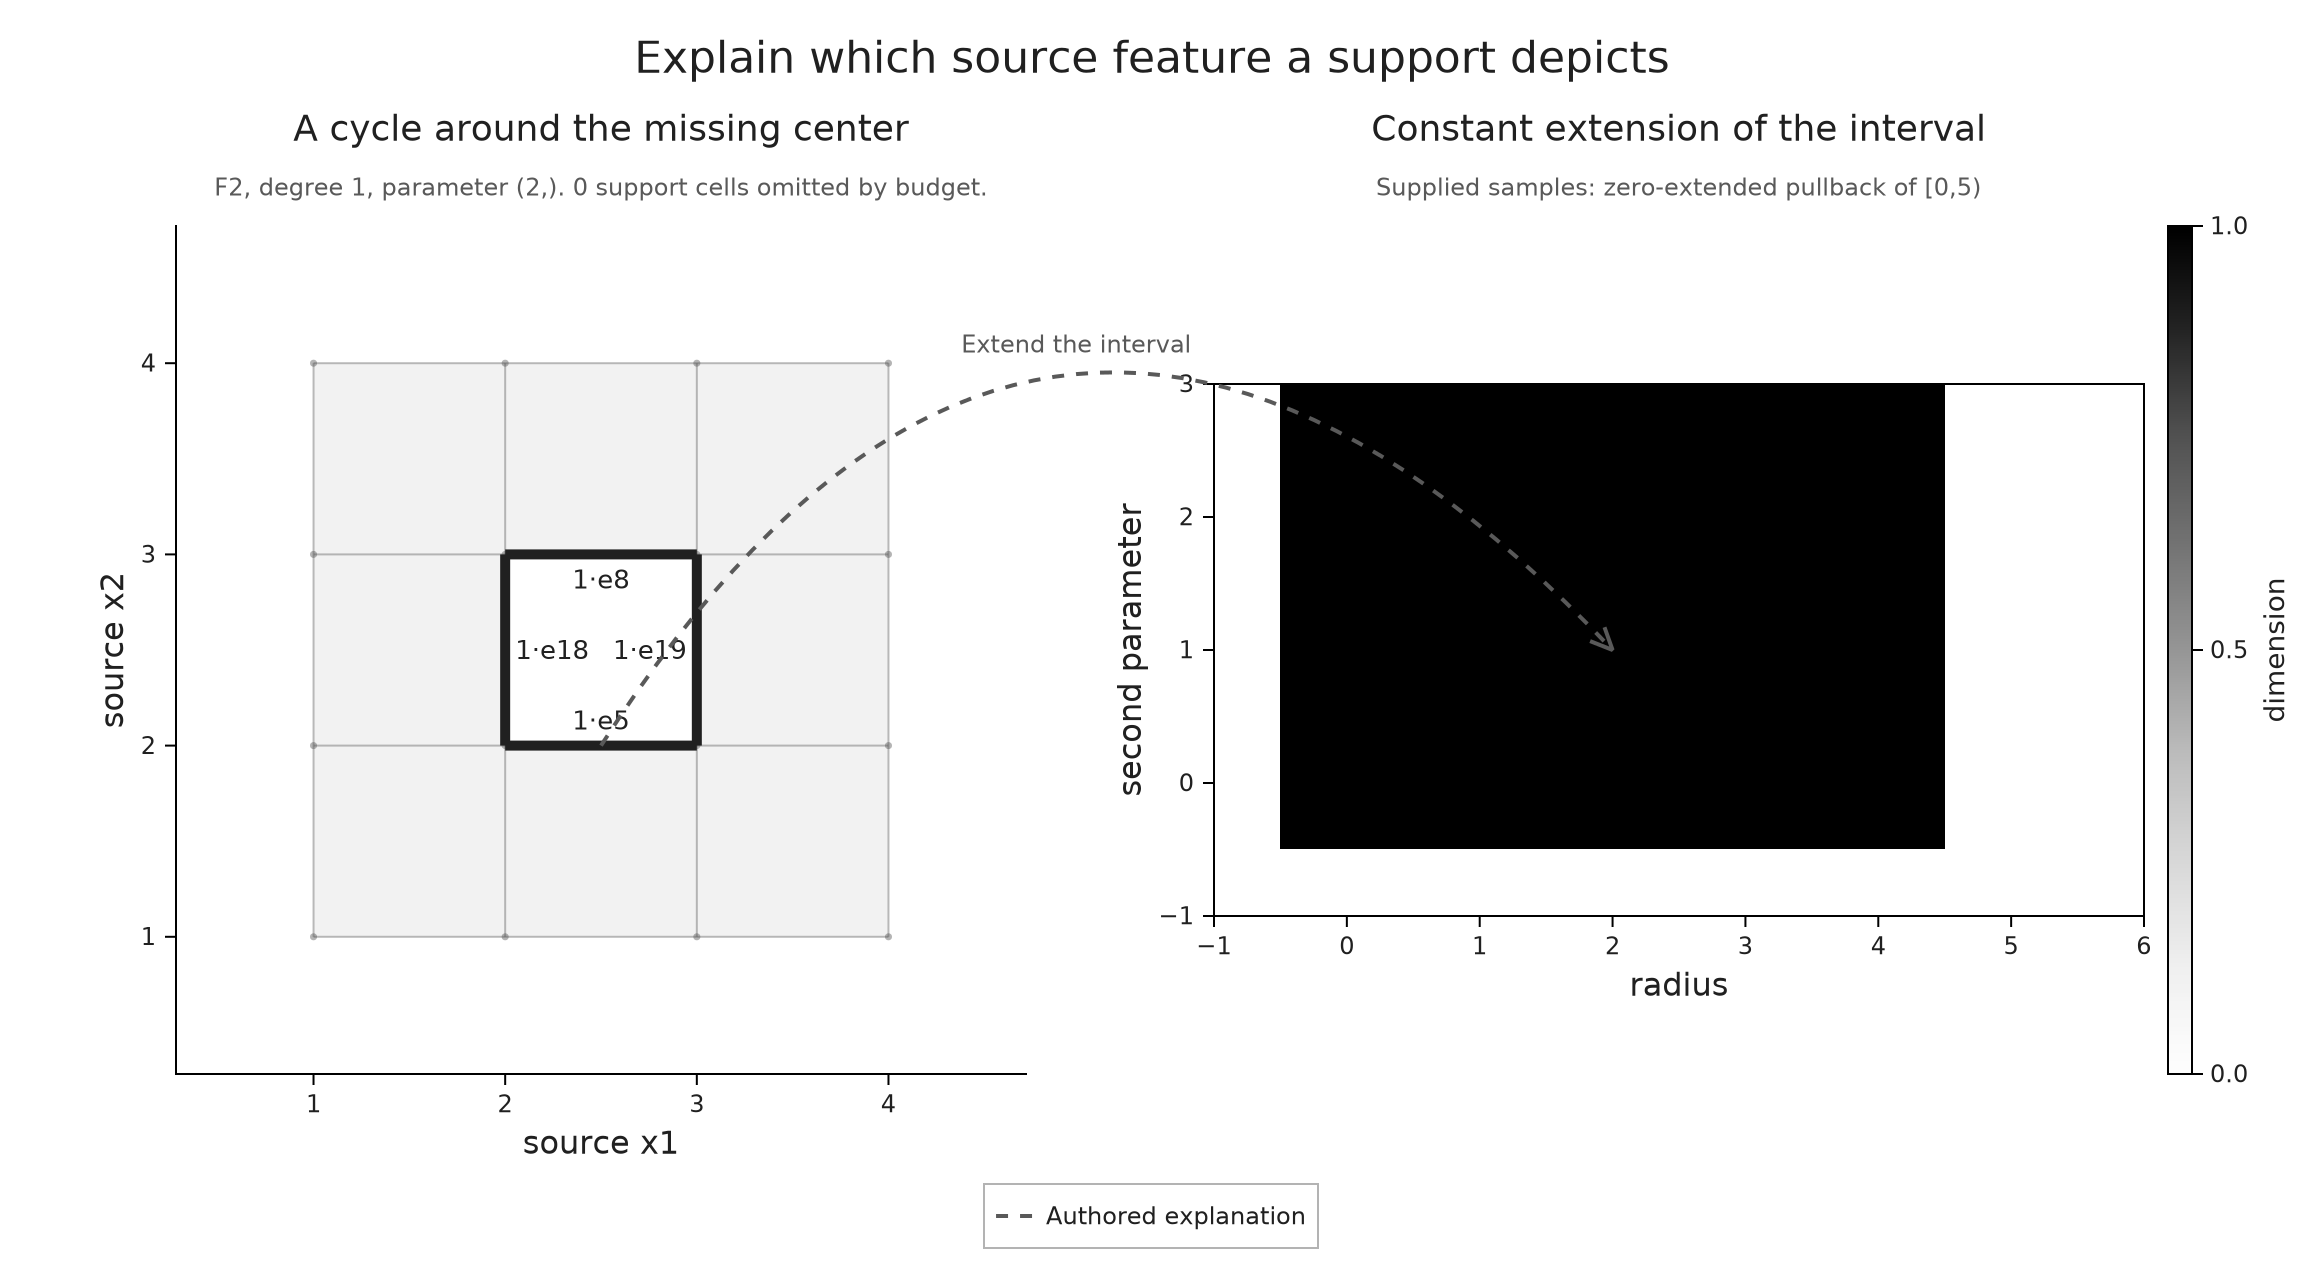

In [8]:
radius = collect(-1:6)
second_parameter = collect(-1:3)
support_values = [Int(0 <= r < 5 && s >= 0) for s in second_parameter, r in radius]
support_context = OP.VisualContext(domain="radius and auxiliary parameter",
    units=("radius", "second parameter"), degree=1, provenance="zero-extended pullback of [0,5)")
support = OP.visual_panel(support_values; x=radius, y=second_parameter,
    quantity="dimension", context=support_context, title="Constant extension of the interval")
support_note = OP.VisualAnnotation(connection.from,
    OP.VisualAnchor(:support; point=(2, 1));
    label="Extend the interval", curve=0.32)
support_figure = OP.compose_visuals((source=source, support=support);
    annotations=(support_note,), title="Explain which source feature a support depicts")
OP.visualize(support_figure)


## Explain a coefficient without asserting another map

Sometimes the connection is an explanation of notation. The matrix below is a supplied presentation fragment: its first column is the vector $(1,-1)$. A point marked $g_1$ denotes that same chosen column in a schematic generator drawing. We use the public specification types for these supplied objects; no decomposition or coordinate grades are inferred.

A matrix anchor follows the actual coefficient label, rather than estimating its position from row and column counts. The dashed arrow tells the reader that this is an authored explanation.

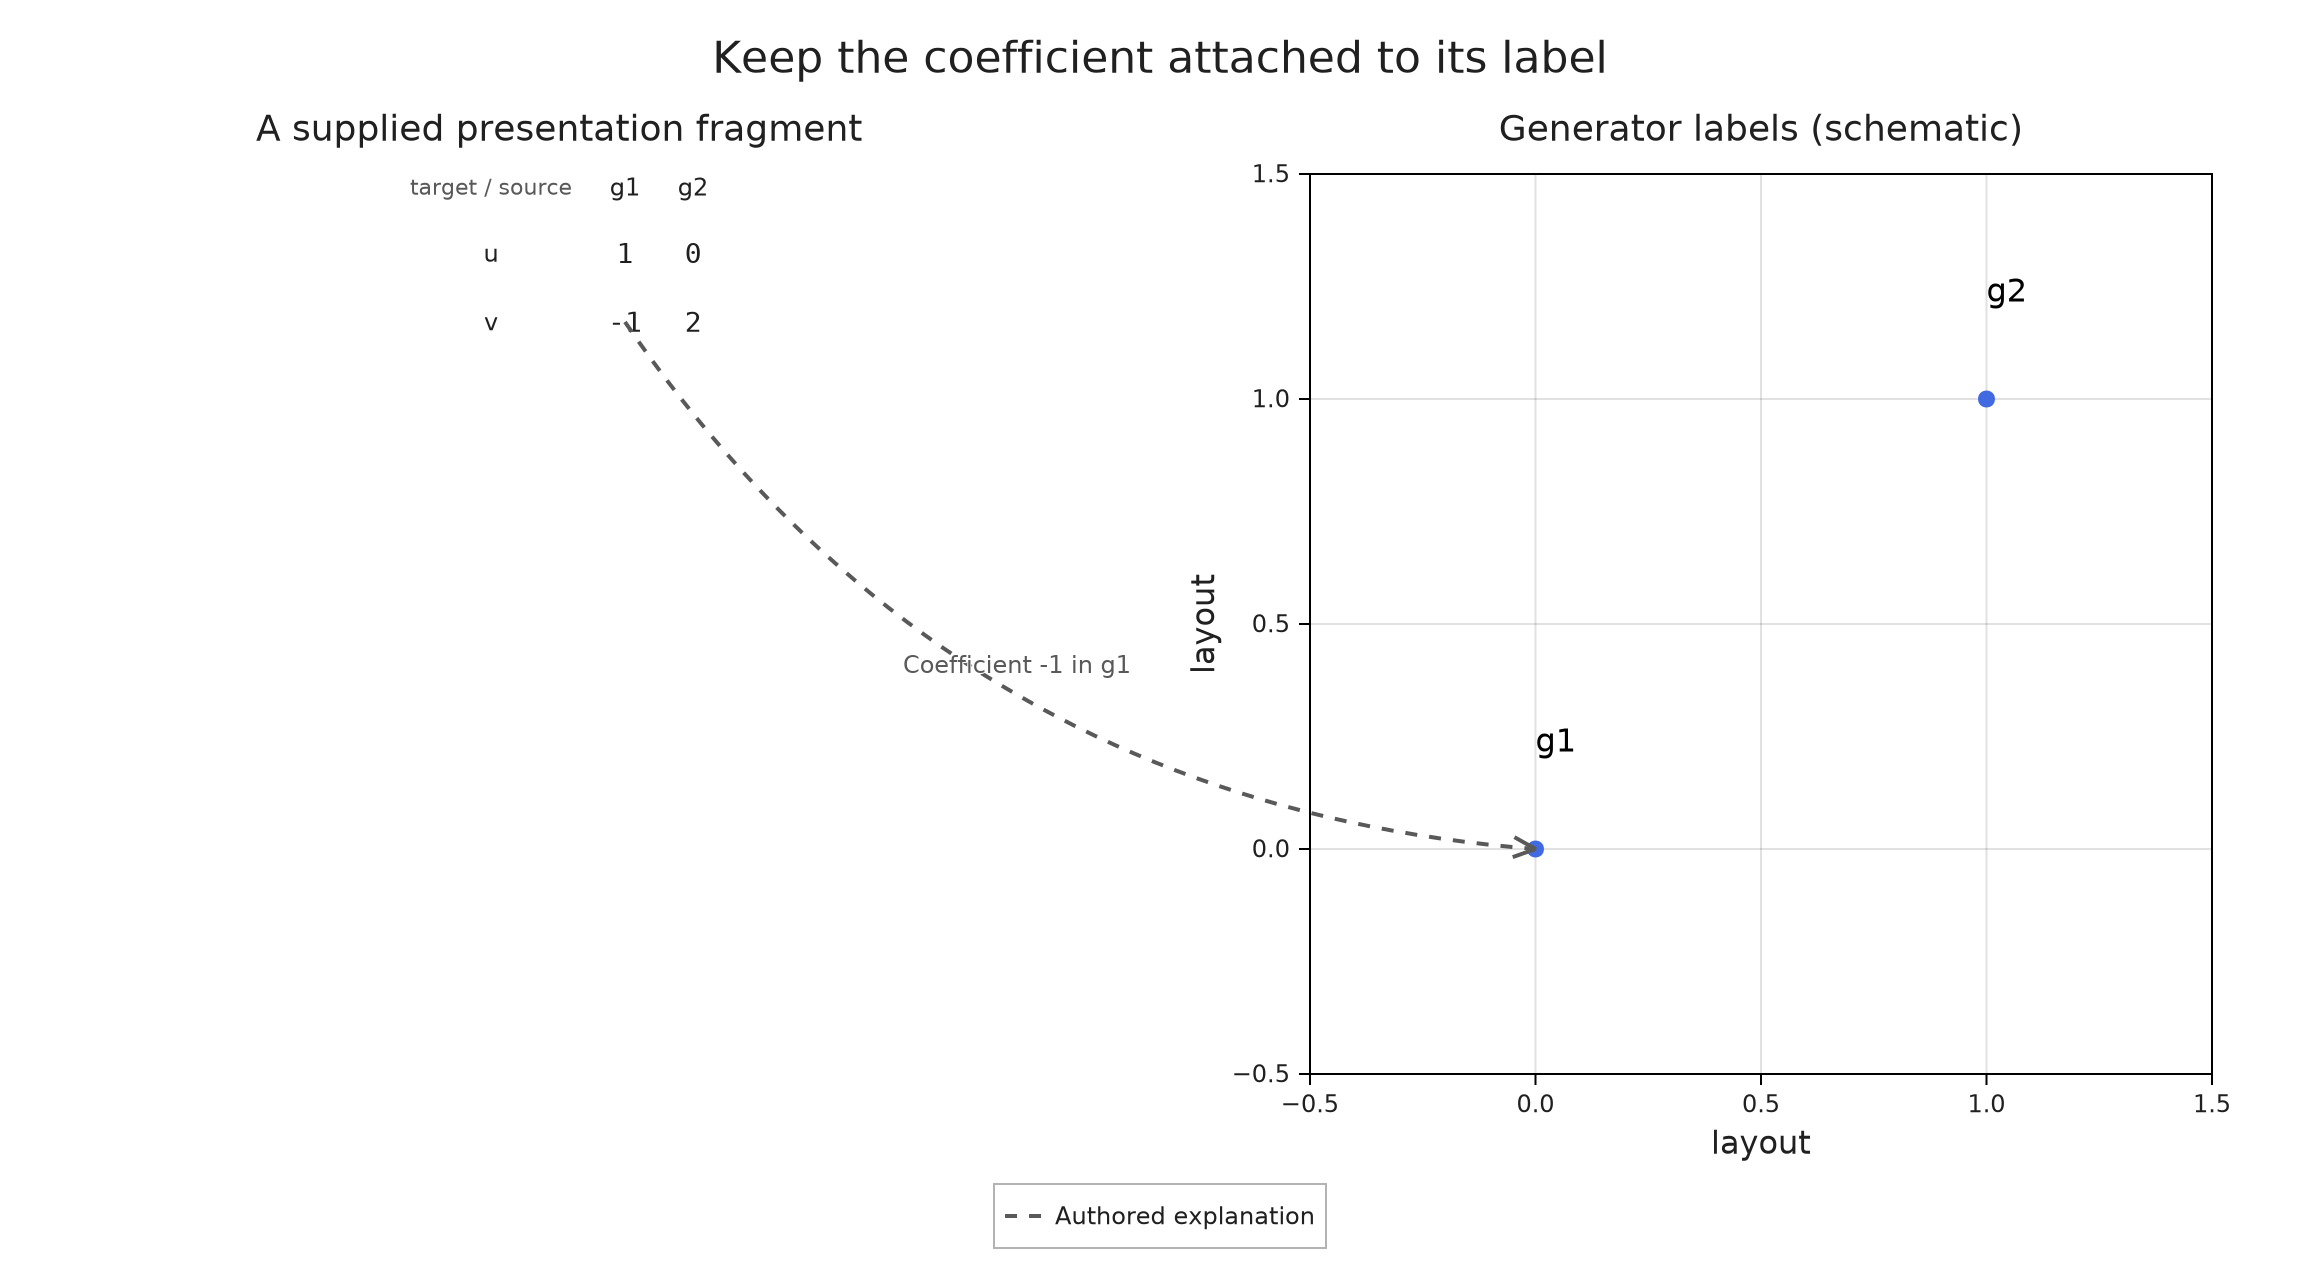

In [9]:
matrix = A.VisualizationSpec(:presentation_fragment;
    title="A supplied presentation fragment",
    layers=A.AbstractVisualizationLayer[
        A.MatrixLayer(["1" "0"; "-1" "2"], ["u", "v"], ["g1", "g2"])],
    metadata=(panel_style=:matrix,))
generators = A.VisualizationSpec(:generator_schematic;
    title="Generator labels (schematic)",
    layers=A.AbstractVisualizationLayer[
        A.PointLayer([(0.0, 0.0), (1.0, 1.0)], :royalblue, 1.0, 12.0),
        A.TextLayer(["g1", "g2"], [(0.0, 0.2), (1.0, 1.2)], :black, 16.0)],
    axes=(xlabel="layout", ylabel="layout", xlimits=(-0.5, 1.5),
          ylimits=(-0.5, 1.5), aspect=:equal))
coefficient_note = OP.VisualAnnotation(
    OP.VisualAnchor(:matrix; target=(:matrix, 2, 1)),
    OP.VisualAnchor(:generators; target=(:layer, 1, 1));
    label="Coefficient -1 in g1", curve=-0.12)
algebra_figure = OP.compose_visuals((matrix=matrix, generators=generators);
    annotations=(coefficient_note,), title="Keep the coefficient attached to its label")
OP.visualize(algebra_figure)

## Compare with one scale

A shared color scale is useful when panels display the same quantity. Compare our dimensions with a second supplied table of twice those dimensions. We explicitly label this as an intentional comparison of different constructions. The colorbars now have the same numerical range; a shade means the same number on both panels. This says nothing about a natural isomorphism or an identification of their classes.

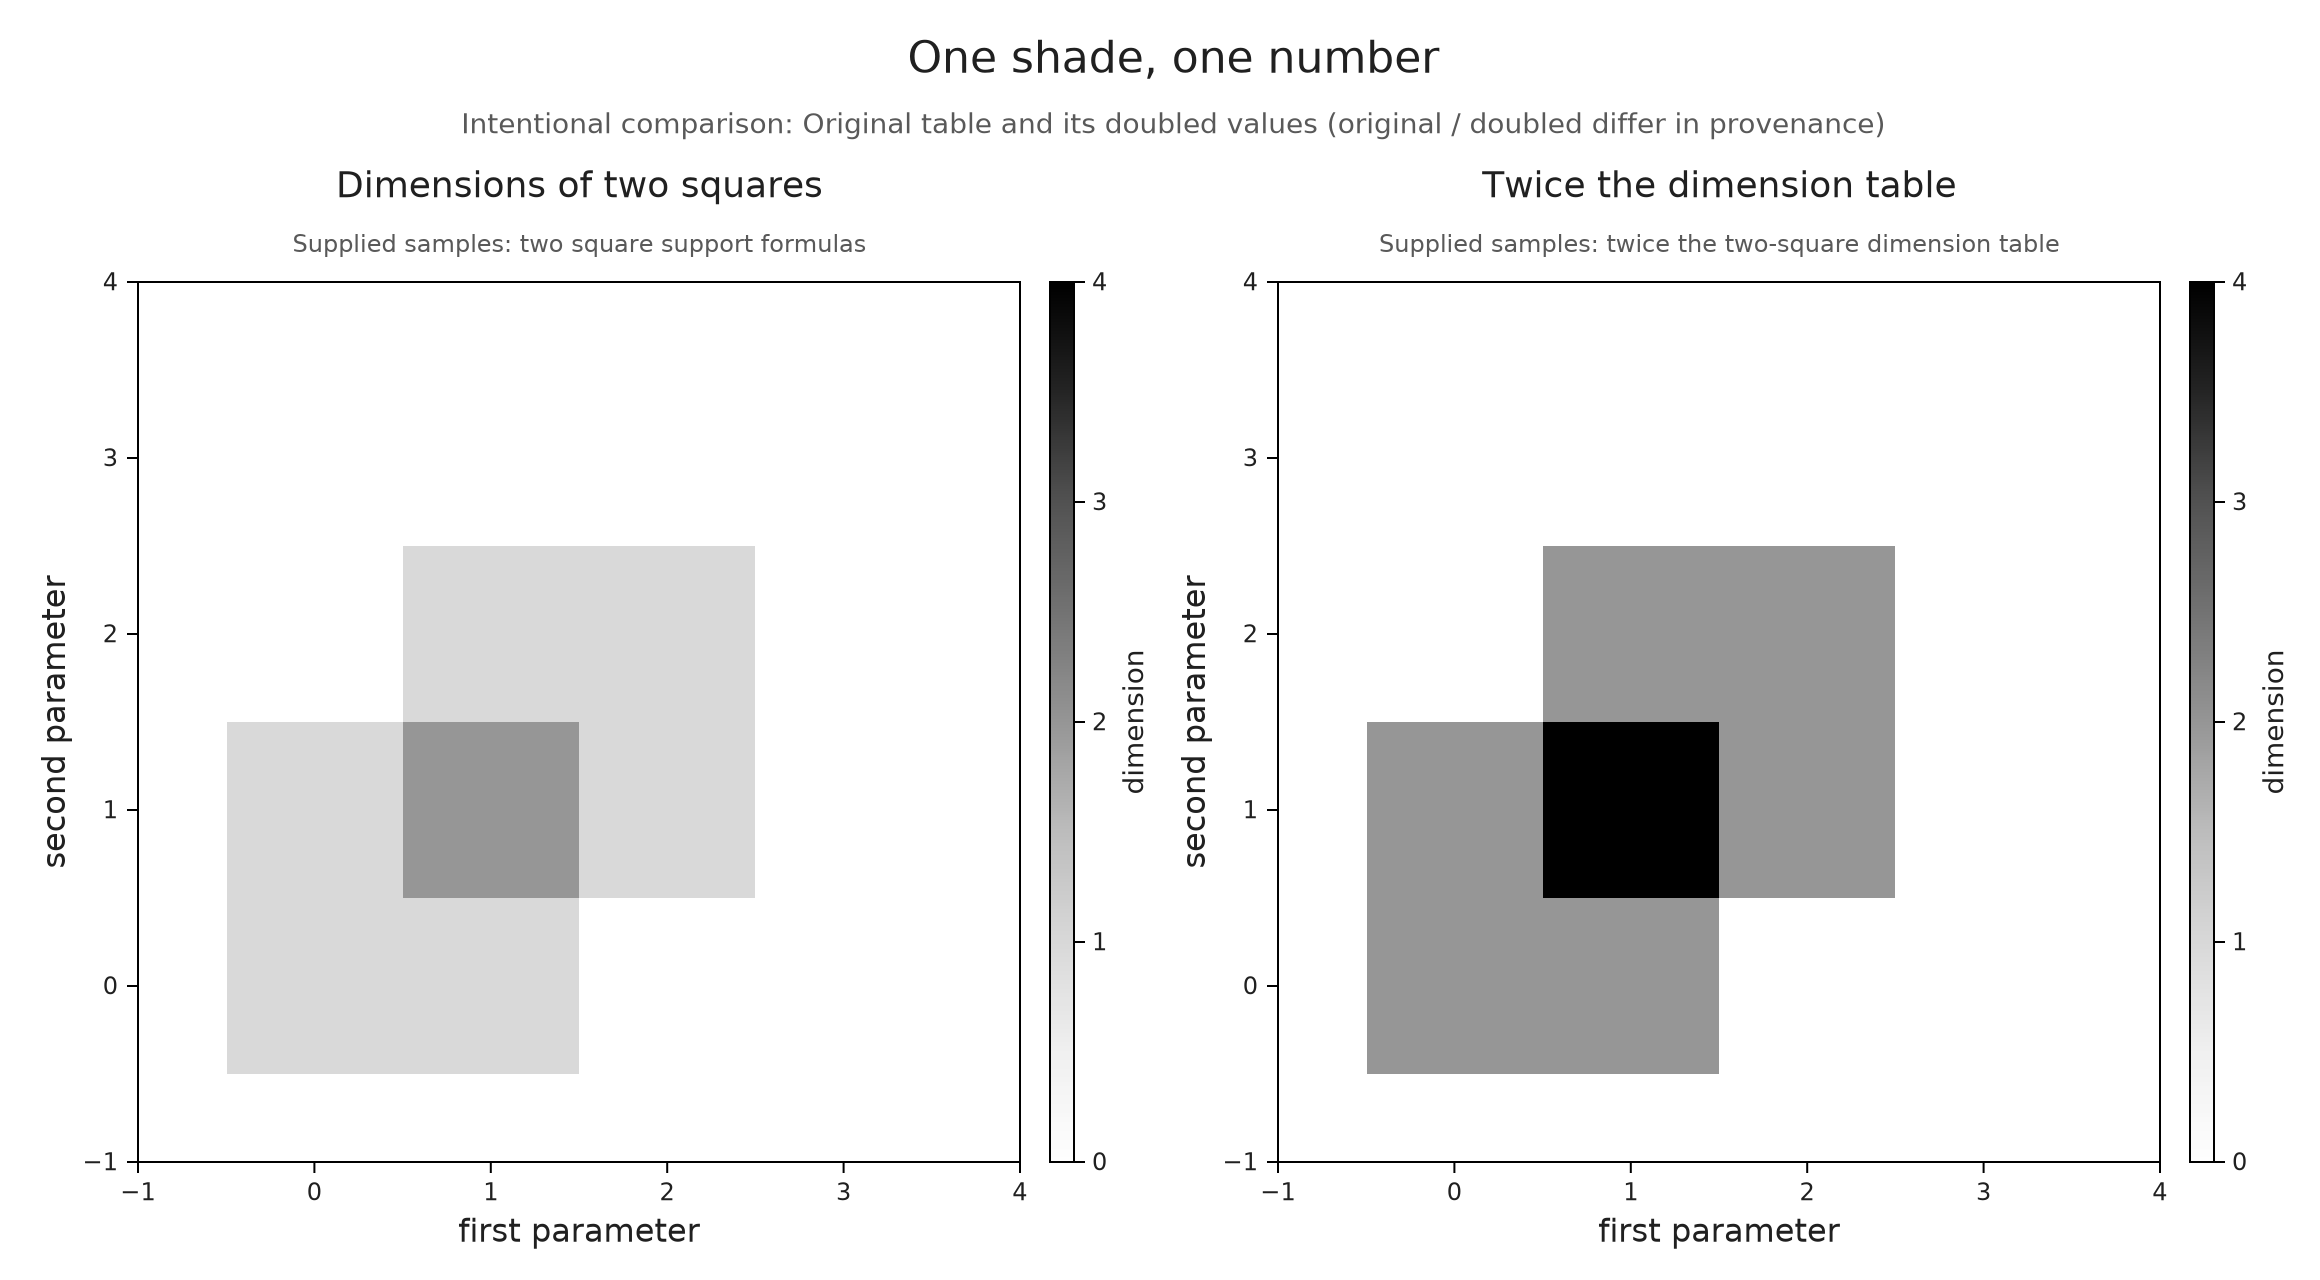

In [10]:
double_context = OP.VisualContext(domain="two-square parameter plane",
    units=context.units, provenance="twice the two-square dimension table")
doubled = OP.visual_panel(2 .* permutedims(dimensions); x=xs, y=ys,
    quantity="dimension", context=double_context, title="Twice the dimension table")
comparison = OP.compose_visuals((original=background, doubled=doubled);
    link_axes=((:original, :doubled),), link_colors=((:original, :doubled),),
    comparison="Original table and its doubled values", title="One shade, one number")
OP.visualize(comparison)

Try changing the second context's first unit to `millimeters`. Without the `comparison` explanation, composing linked views must fail. With an explanation it is an intentional juxtaposition; the library does not convert the coordinates for you. The [composition reference](../src/reference/visualization.md#composing-views-and-annotations) gives the exact contract.

## Optional: export the selected figure

Static figures preserve the chosen view. Save PNG, SVG or PDF for a manuscript, or HTML for a browser. Composed HTML contains a responsive SVG and an accessible list of annotation meanings: it can be reopened with Julia closed and the network disconnected. Resizing scales the entire figure, so arrows remain attached. It does not recompute classes or provide a live inspector.

The following cell uses a temporary directory so repeated execution does not overwrite your work. Replace it with your own output folder when keeping the files.

In [11]:
output_directory = mktempdir()
exports = [OP.save_visual(output_directory, "cycle-connection", source_figure; format)
           for format in (:png, :svg, :pdf, :html)]
[(OP.export_format(result), basename(OP.export_path(result))) for result in exports]

4-element Vector{Tuple{Symbol, String}}:
 (:png, "cycle-connection.png")
 (:svg, "cycle-connection.svg")
 (:pdf, "cycle-connection.pdf")
 (:html, "cycle-connection.html")

Style changes stay separate from mathematical choices. Here a grayscale export uses the same endpoints, coefficients and checked relationship.

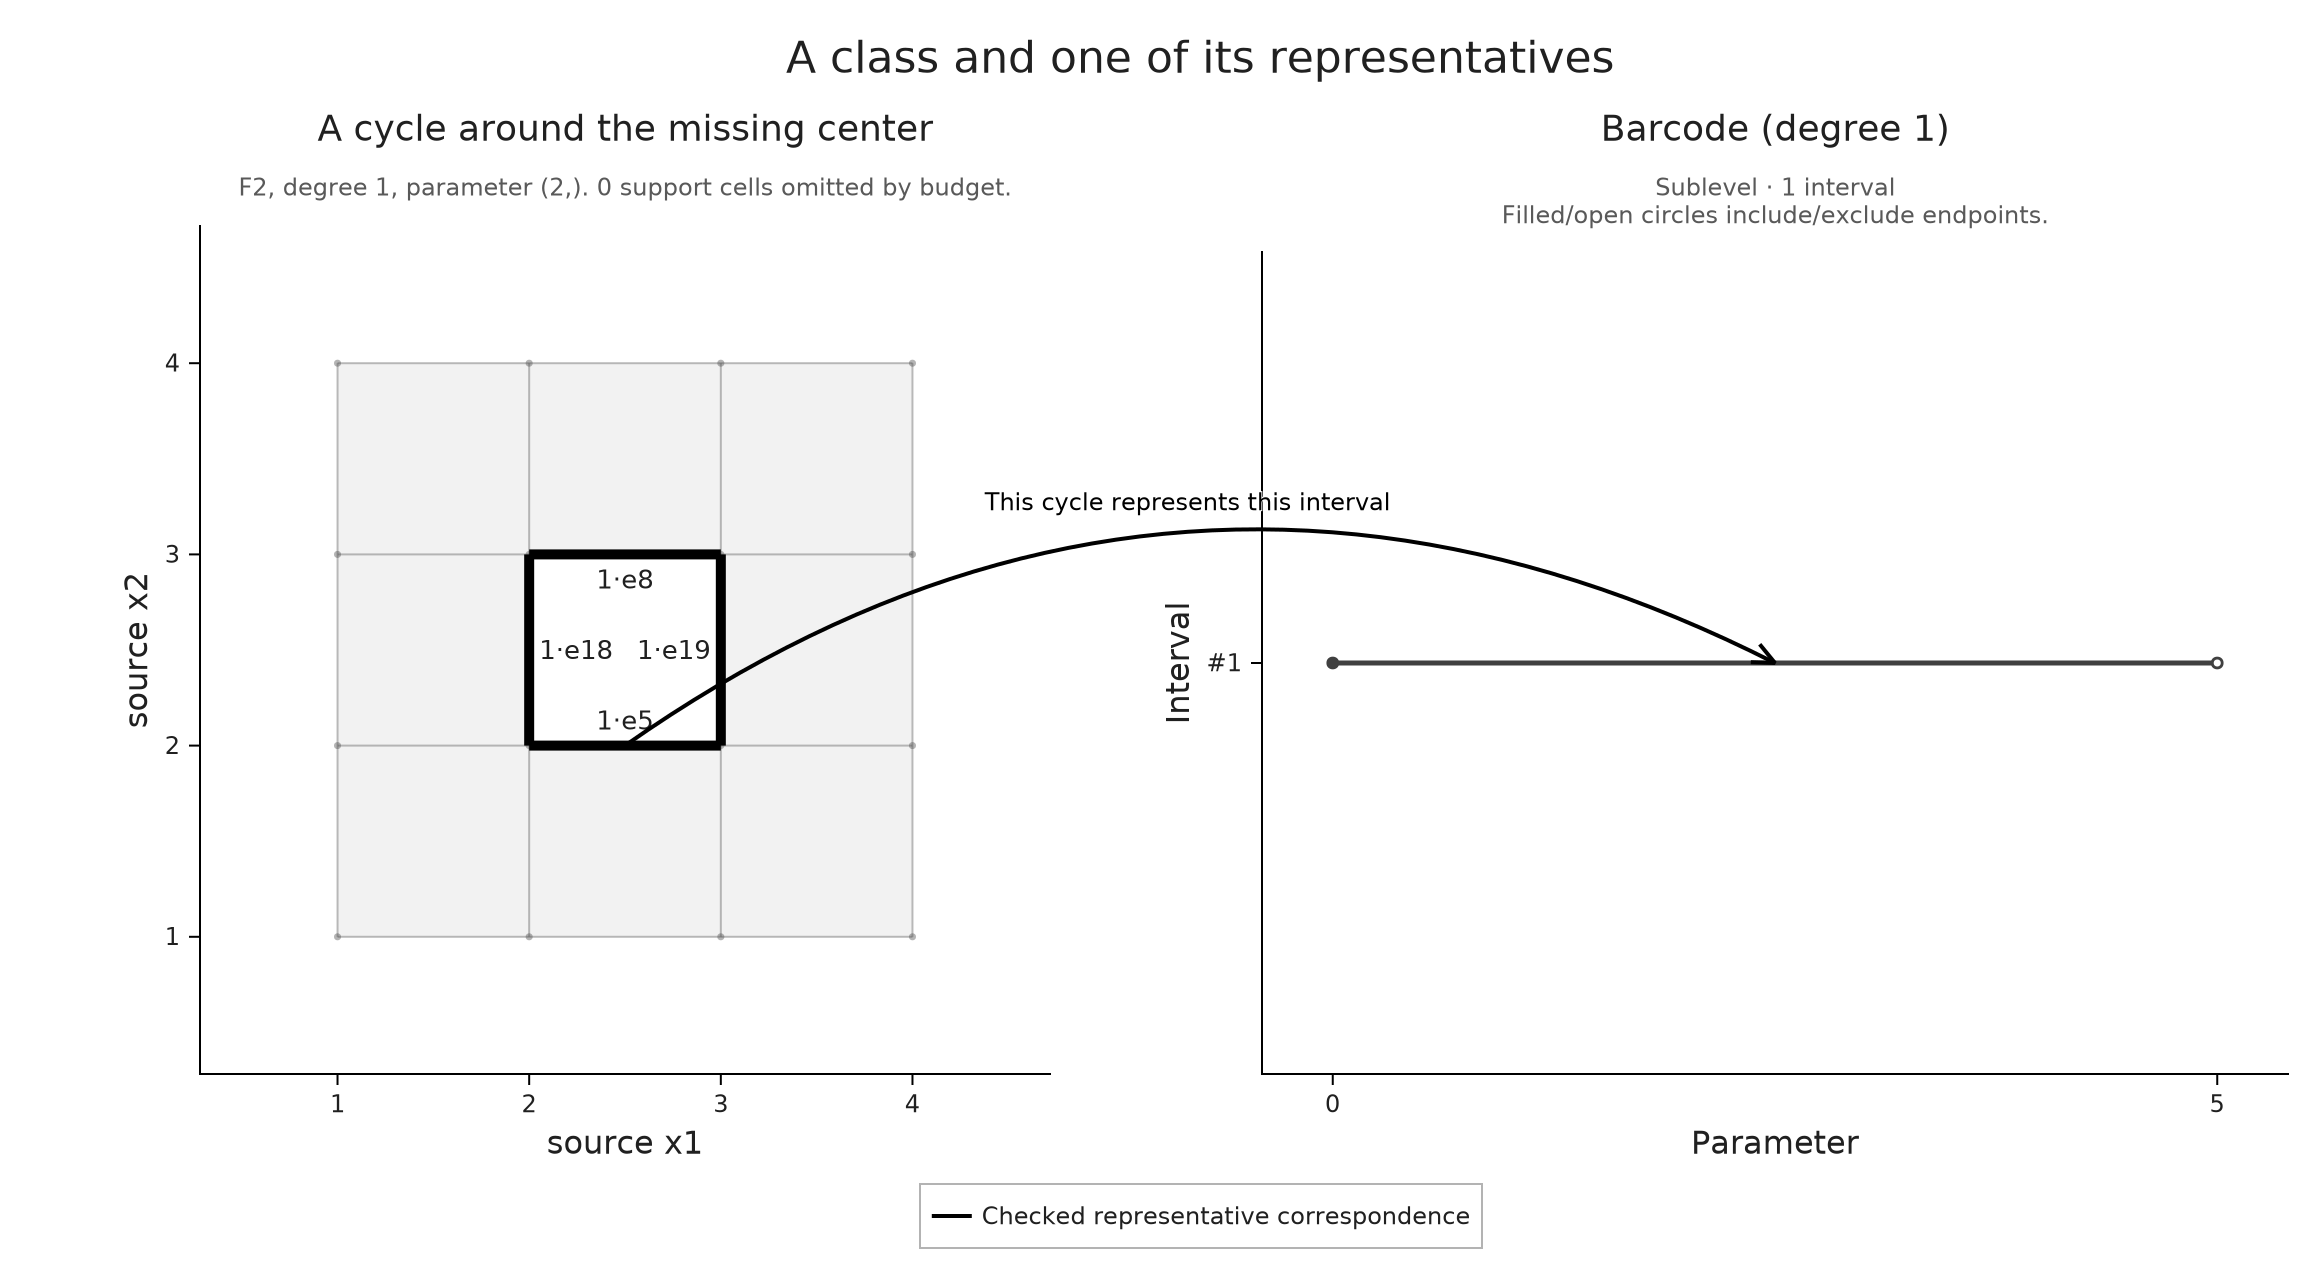

In [12]:
OP.visualize(source_figure; style=OP.VisualStyle(palette=:grayscale))

For pan and zoom while Julia runs, load WGLMakie and call `visualize(source_figure; backend=:wglmakie)`. The annotations follow the live axis limits. A cropped-out endpoint hides its annotation; it never moves onto another feature. The offline HTML instead preserves the selected fixed view.

We have kept three things distinct: computed scalar values, a checked representative correspondence, and an authored explanation. To keep several prepared selections, reopen their exact readouts, or resume supported queries in Julia, continue with [Keeping a selected mathematical view](live_inspection.ipynb). Its saved-session HTML offers a finite state selector; the composed HTML above preserves one selected figure. To retain a mathematical object independently of its view, consult the [integration and interchange guide](../optional_integrations.md).